# Notebook 01 — Data preparation
Run cells **top to bottom** using Shift+Enter. Before starting, put `marketing_campaign.csv` into the `data` folder. Do not replace the raw CSV.

## 1. Import libraries and locate folders
`pandas` works with tables; `seaborn` and `matplotlib` draw graphs; `pathlib` creates reliable file paths.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

current = Path.cwd()
ROOT = current if (current / "data").exists() else current.parent
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT.resolve())

Project root: /home/darknight/Projects/learning/Customer-Segmentation-Project


## 2. Read the raw dataset
The Kaggle file looks like a CSV but uses **tab characters**, so use `sep="\t"`. `head()` shows the first five rows; `shape` shows row and column counts.

In [3]:
raw_file = DATA_DIR / "marketing_campaign.csv"
if not raw_file.exists():
    raise FileNotFoundError(f"Download the Kaggle CSV and put it here: {raw_file}")

df = pd.read_csv(raw_file, sep="\t")
df.columns = df.columns.str.strip()
print("Raw shape (rows, columns):", df.shape)
display(df.head())
print("Column names:", list(df.columns))

Raw shape (rows, columns): (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


Column names: ['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


## 3. Check missing values and duplicates
Note that the original dataset can have missing `Income` values. We do **not** use `Income` to train this model, so we will not delete customers solely because that field is empty.

In [4]:
print("Top missing-value counts:")
print(df.isna().sum().sort_values(ascending=False).head(10))
print("Repeated customer IDs:", df.duplicated(subset=["ID"]).sum())

Top missing-value counts:
Income            24
ID                 0
Year_Birth         0
Education          0
Marital_Status     0
Kidhome            0
Teenhome           0
Dt_Customer        0
Recency            0
MntWines           0
dtype: int64
Repeated customer IDs: 0


## 4. Clean the behavior columns
Use only spending, purchase counts, and recency. Remove duplicate customer IDs, rows missing required behavior values, and impossible negative values. Keep the rest of the original information for later interpretation.

In [5]:
product_cols = [
    "MntWines", "MntFruits", "MntMeatProducts",
    "MntFishProducts", "MntSweetProducts", "MntGoldProds"
]
purchase_cols = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
behavior_cols = product_cols + purchase_cols + ["Recency"]
required = ["ID"] + behavior_cols
missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise ValueError(f"Dataset is missing these columns: {missing_cols}")

before = len(df)
df = df.drop_duplicates(subset=["ID"]).copy()
for col in behavior_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=behavior_cols).copy()
df = df.loc[(df[behavior_cols] >= 0).all(axis=1)].copy()
print(f"Rows before: {before}; rows after cleaning: {len(df)}")
print("Missing values in required behavior columns:", int(df[behavior_cols].isna().sum().sum()))

Rows before: 2240; rows after cleaning: 2240
Missing values in required behavior columns: 0


## 5. Feature engineering
A **feature** is a numerical property of a customer. We create total category spending, total channel purchase counts (our purchase-frequency proxy), and six spending proportions (product preferences). `NumDealsPurchases` is excluded from purchase counts because deal purchases could overlap with channel counts. These are **historical** figures, not current monthly rates.

In [6]:
df["Total_Spending"] = df[product_cols].sum(axis=1)
df["Purchase_Frequency"] = df[purchase_cols].sum(axis=1)

category_names = {
    "MntWines": "Wine", "MntFruits": "Fruit", "MntMeatProducts": "Meat",
    "MntFishProducts": "Fish", "MntSweetProducts": "Sweets", "MntGoldProds": "Gold"
}
df["Preferred_Category"] = df[product_cols].idxmax(axis=1).map(category_names)
df.loc[df["Total_Spending"] == 0, "Preferred_Category"] = "No recorded spending"

safe_spending = df["Total_Spending"].replace(0, np.nan)
for col in product_cols:
    df[col + "_Share"] = (df[col] / safe_spending).fillna(0)

display(df[["ID", "Total_Spending", "Purchase_Frequency", "Recency", "Preferred_Category"]].head())
print("Average spending:", round(df["Total_Spending"].mean(), 2))
print("Average purchase count:", round(df["Purchase_Frequency"].mean(), 2))

,ID,Total_Spending,Purchase_Frequency,Recency,Preferred_Category
0,5524,1617,22,58,Wine
1,2174,27,4,38,Wine
2,4141,776,20,26,Wine
3,6182,53,6,26,Meat
4,5324,422,14,94,Wine


Average spending: 605.8
Average purchase count: 12.54


## 6. Make EDA charts
EDA means **exploratory data analysis**. These charts show distributions before clustering and help you understand the data. Each graph is saved to `outputs/figures` for inclusion in the project README.

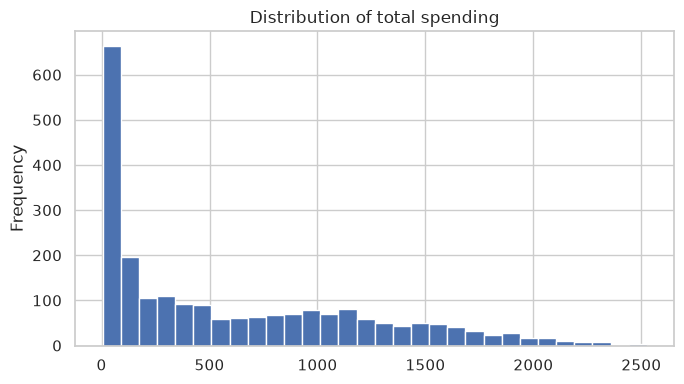

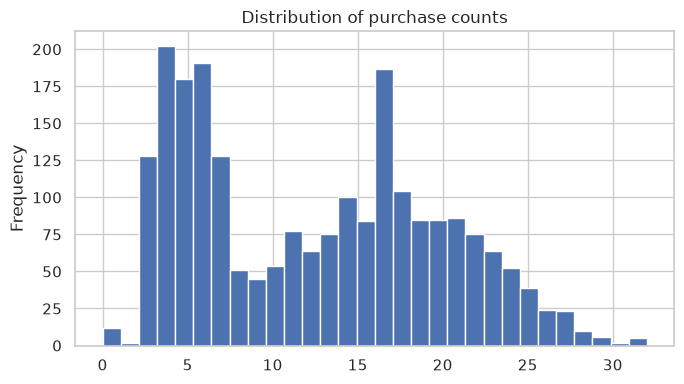

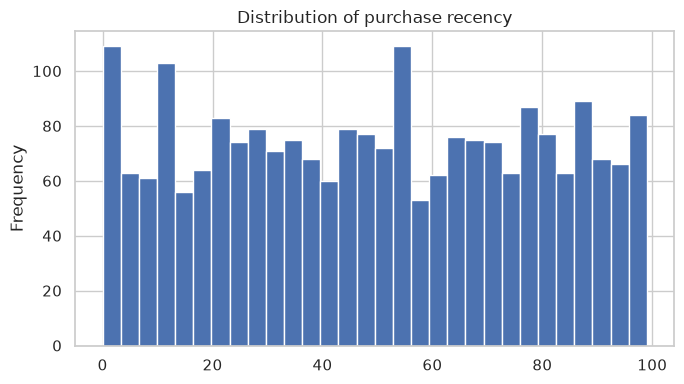

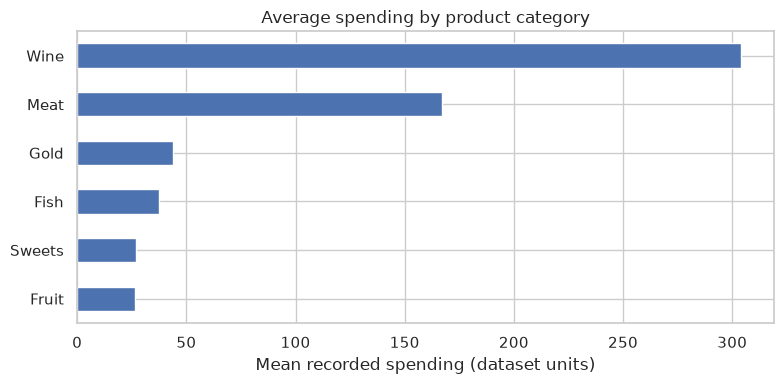

In [7]:
sns.set_theme(style="whitegrid")

for col, title, filename in [
    ("Total_Spending", "Distribution of total spending", "eda_total_spending.png"),
    ("Purchase_Frequency", "Distribution of purchase counts", "eda_purchase_frequency.png"),
    ("Recency", "Distribution of purchase recency", "eda_recency.png"),
]:
    plt.figure(figsize=(7, 4))
    df[col].plot(kind="hist", bins=30)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=180)
    plt.show()

average_products = df[product_cols].mean().rename(index=category_names)
plt.figure(figsize=(8, 4))
average_products.sort_values().plot(kind="barh")
plt.xlabel("Mean recorded spending (dataset units)")
plt.title("Average spending by product category")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_product_categories.png", dpi=180)
plt.show()

## 7. Export the cleaned file
`index=False` stops pandas from creating an extra unnamed index column. Confirm the file exists in `data/`, then move on to Notebook 02 yourself.

In [9]:
clean_file = DATA_DIR / "clean_customers.csv"
df.to_csv(clean_file, index=False)
print("Saved:", clean_file.resolve())
print("Total rows exported:", len(df))
assert clean_file.exists()

Saved: /home/darknight/Projects/learning/Customer-Segmentation-Project/data/clean_customers.csv
Total rows exported: 2240


### Summary of the preparation stage
We read the original Kaggle data, verified the fields, removed invalid behavior rows, derived three useful customer-level behavior indicators, created charts, and saved one cleaned CSV. The clustering notebook will use this CSV.